# Machine Learning
**Pset 3**

Jay Ballesteros

In [1]:
import os
import numpy as np
import pandas as pd

# Sci-kit learn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression,LinearRegression, Lasso
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import cross_val_score, cross_validate
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.linear_model import LinearRegression

# Statsmodels
import statsmodels.api as sm

# Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

# Iterator building blocks
# example: combinations('ABCD', 2) --> AB AC AD BC BD CD
from itertools import combinations

# Q1

**We continue to consider the use of a logistic regression model to predict the probability of default using income and balance on the Default data set. In particular, we will now compute estimates for the standard errors of the income and balance logistic regression coefficients in two different ways: (1) using the bootstrap, and (2) using the standard formula for computing the standard errors in the the sm.GLM() function.1 Do not forget to set a random seed (equal to 23) before beginning your analysis.**

In [2]:
np.random.seed(23)
rng = np.random.default_rng(23)

In [3]:
PATH = ("data")

df_default = pd.read_csv(os.path.join(PATH, 'Data-Default.csv'))

In [4]:
encoding_dict = {'Yes': 1,'No': 0}
for col in ['default', 'student']:
    df_default[col] = df_default[col].map(encoding_dict)

df_default.head()

,default,student,balance,income
0,0,0,729.526495,44361.625074
1,0,1,817.180407,12106.134700
2,0,0,1073.549164,31767.138947
3,0,0,529.250605,35704.493935
4,0,0,785.655883,38463.495879


## (a)

**Using the sm.GLM() function and the .summary() method, determine the estimated standard errors for the coefficients associated with income and balance in a multiple logistic regression model that uses both predictors.**

In [5]:
X = df_default[['balance', 'income']]
X = sm.add_constant(X)

y = df_default['default']

glm_model = sm.GLM(y, X, family=sm.families.Binomial())
glm_results = glm_model.fit()

print(glm_results.summary())
print(glm_results.bse[["balance", "income"]]) # standard errors 

                 Generalized Linear Model Regression Results                  
Dep. Variable:                default   No. Observations:                10000
Model:                            GLM   Df Residuals:                     9997
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -789.48
Date:                Thu, 12 Nov 2026   Deviance:                       1579.0
Time:                        20:43:34   Pearson chi2:                 6.95e+03
No. Iterations:                     9   Pseudo R-squ. (CS):             0.1256
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -11.5405      0.435    -26.544      0.0

In [6]:
output_coefficient = glm_results.bse[["balance", "income"]]
output_coefficient

balance    0.000227
income     0.000005
dtype: float64

## (b)

**Write a function, boot_fn(), that takes as input the Default data set as well as an index of the observations, and that outputs the coefficient estimates for income and balance in the multiple logistic regression model.**

In [7]:
def boot_fn(df_data, index, features=['balance', 'income'], target='default'):
    '''
    Fits a logistic regression (with a constant) on the observations in `index`
    and returns the coefficients for balance and income.

    Inputs:
        - df_data (pd.DataFrame): data with 0/1 target column
        - index (array-like): row labels forming the (bootstrap) sample
        - features (list of str): predictor names
        - target (str): target name

    Output:
        - coefficients (list of float): [balance coef, income coef]
    '''
    X = sm.add_constant(df_data[features].loc[index])
    y = df_data[target].loc[index]

    results = sm.GLM(y, X, family=sm.families.Binomial()).fit()
    return results.params[['balance', 'income']].tolist()


In [8]:
boot_fn(df_default, df_default.index)

[0.0056471029503165, 2.0808975528987273e-05]

## (c)

**Following the bootstrap example in the lab, use your boot_fn() function to estimate the standard errors of the logistic regression coefficients for income and balance. Please draw 1,000 bootstrap samples when bootstrapping your standard errors.**

In [9]:
B = 1000
boot_coefs = np.array([
    boot_fn(df_default, rng.choice(df_default.index, size=len(df_default), replace=True))
    for _ in range(B)
])

boot_se = boot_coefs.std(axis=0, ddof=1)
print('boot SE balance:', boot_se[0], ' income:', boot_se[1])
print('GLM SE balance:', glm_results.bse['balance'], ' income:', glm_results.bse['income'])

boot SE balance: 0.00022916692851137507  income: 4.959666149005631e-06
GLM SE balance: 0.00022738138440210384  income: 4.985245458257304e-06


## (d)
**Comment on the estimated standard errors obtained using the sm.GLM() function and using the bootstrap.**

The difference between both SE are very close. That makes sense because the sample is big (10,000 obs) and the logistic model is a reasonable fit, so the GLM formula (which relies on the model assumptions being right) and the bootstrap (which doesn't) end up giving almost the same answer.


# 2

**We will now perform cross-validation on a simulated data set.**

## (a)

**Generate a simulated data set as follows:**


````
rng = np.random.default_rng(1)
x = rng.normal(size=100)
y = x - 2 * x**2 + rng.normal(size=100)
````

**In this data set, what is n and what is p? Write out the model used to generate the data in equation form.**

`n` is 100. `p` is just 1, because `x` is the only predictor here. 

In equation form:

$$
y_i = x_i - 2x_i^2 + \varepsilon_i,
$$

where

$$
\varepsilon_i \sim N(0, 1)
$$

In [10]:
rng = np.random.default_rng(1)
x = rng.normal(size=100)
y = x - 2 * x**2 + rng.normal(size=100)

## (b) 
**Create a scatterplot of X against Y . Comment on what you find.**

The relationship between x and y is non-linear (it looks like an upside-down parabola). Y rises as X goes from negative values up to around 0 (the peak is at roughly x = 0.25), and after that Y decreases as X keeps increasing. In this scenario, a straight line will underfit.

<Axes: >

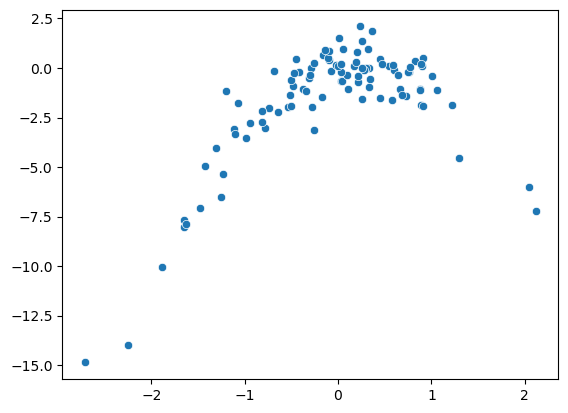

In [11]:
sns.scatterplot(x=x, y=y)

## (c)

**Using the simulated data you generated in Question (2a), set a random seed equal to 10, then compute the LOOCV errors that result from fitting the following four models using least squares:**

1. Y= β0 + β1X + ε: 6.633029839181983
2. Y= β0 + β1X + β2X2 + ε: 1.1229368563419684
3. Y= β0 + β1X + β2X2 + β3X3 + ε: 1.3017965489358874
4. Y= β0 + β1X + β2X2 + β3X3 + β4X4 + ε: 1.332394269417934

**Note you may find it helpful to use the data.frame() function to create a single data set containing both X and Y .**

In [12]:
rng = np.random.default_rng(10)

In [13]:
df = pd.DataFrame({"X": x, "Y": y})  # data from (2a)

df["X2"] = df["X"] ** 2
df["X3"] = df["X"] ** 3
df["X4"] = df["X"] ** 4

1. Y= β0 + β1X + ε

In [14]:
scores = cross_val_score(
    LinearRegression(),
    df[["X"]],          
    df["Y"],            
    cv=LeaveOneOut(),
    scoring="neg_mean_squared_error",
)
print(-scores.mean())

6.633029839181983


2. Y= β0 + β1X + β2X2 + ε

In [15]:
scores = cross_val_score(
    LinearRegression(),
    df[["X", "X2"]],
    df["Y"],         
    cv=LeaveOneOut(),
    scoring="neg_mean_squared_error",
)
print(-scores.mean())

1.1229368563419684


3. Y= β0 + β1X + β2X2 + β3X3 + ε

In [16]:
scores = cross_val_score(
    LinearRegression(),
    df[["X", "X2", "X3"]],
    df["Y"],         
    cv=LeaveOneOut(),
    scoring="neg_mean_squared_error",
)
print(-scores.mean())

1.3017965489358874


4. Y= β0 + β1X + β2X2 + β3X3 + β4X4 + ε.

In [17]:
scores = cross_val_score(
    LinearRegression(),
    df[["X", "X2", "X3", "X4"]],
    df["Y"],         
    cv=LeaveOneOut(),
    scoring="neg_mean_squared_error",
)
print(-scores.mean())

1.332394269417934


## (d)

**Repeat Question (2c) using a random seed equal to 20, and report your results. Are your results the same as what you got in Question (2c)? Why?**

They are the same! Because LOOCV doesn't have any randomness: each of the n folds leaves out exactly one observation, so the splits are always the same no matter the seed. Same data + same splits = same errors.

In [18]:
rng = np.random.default_rng(20)

In [19]:
df["X2"] = df["X"] ** 2
df["X3"] = df["X"] ** 3
df["X4"] = df["X"] ** 4

In [20]:
scores = cross_val_score(
    LinearRegression(),
    df[["X"]],          
    df["Y"],            
    cv=LeaveOneOut(),
    scoring="neg_mean_squared_error",
)
print(-scores.mean())

6.633029839181983


In [21]:
scores = cross_val_score(
    LinearRegression(),
    df[["X", "X2"]],
    df["Y"],            
    cv=LeaveOneOut(),
    scoring="neg_mean_squared_error",
)
print(-scores.mean())

1.1229368563419684


In [22]:
scores = cross_val_score(
    LinearRegression(),
    df[["X", "X2", "X3"]],
    df["Y"],            
    cv=LeaveOneOut(),
    scoring="neg_mean_squared_error",
)
print(-scores.mean())

1.3017965489358874


In [23]:
scores = cross_val_score(
    LinearRegression(),
    df[["X", "X2", "X3", "X4"]],
    df["Y"],            
    cv=LeaveOneOut(),
    scoring="neg_mean_squared_error",
)
print(-scores.mean())

1.332394269417934


## (e)

**Which of the models in Question (2c) had the smallest LOOCV error? Is this what you expected? Explain your answer.**

The 2nd model (Y= β0 + β1X + β2X2 + ε), and yes. The data was generated with a quadratic model (y = x - 2x² + ε), so the quadratic is the true form. The linear model underfits (high bias), and adding X3 and X4 doesn't reduce bias, it just adds variance, which is why the errors for the 3rd and 4th model go up a bit.

## (f)

**Comment on the statistical significance of the coefficient estimates that results from fitting each of the models in Question (2c) using least squares. Do these results agree with the conclusions drawn based on the cross-validation results?**

Mostly yes. In all the models X and X2 are highly significant (p-values ~0), which matches the true model. In the linear model X is also significant, but that model is misspecified (it's missing X2), so the significance doesn't mean it's a good fit. X3 is not significant in the 3rd model (p = 0.29) nor in the 4th (p = 0.64). The only surprise is X4 in the 4th model, which comes out significant at the 5% level (p = 0.02) even though the true model has no X4 term. That's most likely X4 picking up noise in this particular sample, and LOOCV shows it doesn't help out of sample (the error goes up from 1.12 to 1.33). So overall the results agree with CV: the quadratic is the best model.

In [24]:
rng = np.random.default_rng(1)  # same data as (2a)
x = rng.normal(size=100)
y = x - 2 * x**2 + rng.normal(size=100)

df = pd.DataFrame({"X": x, "Y": y})
print(df.head())

          X         Y
0  0.345584 -0.544554
1  0.821618  0.333950
2  0.330437 -0.013532
3 -1.303157 -4.030442
4  0.905356  0.484861


In [25]:
df["X2"] = df["X"] ** 2
df["X3"] = df["X"] ** 3
df["X4"] = df["X"] ** 4

In [26]:
X = sm.add_constant(df[["X"]])
fit = sm.OLS(df["Y"], X).fit()
print(fit.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.4650      0.247     -5.937      0.000      -1.955      -0.975
X              1.9494      0.289      6.752      0.000       1.376       2.522


In [27]:
X = sm.add_constant(df[["X", "X2"]])
fit = sm.OLS(df["Y"], X).fit()
print(fit.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0728      0.119     -0.611      0.543      -0.309       0.164
X              0.9663      0.126      7.647      0.000       0.715       1.217
X2            -2.0047      0.091    -22.072      0.000      -2.185      -1.824


In [28]:
X = sm.add_constant(df[["X", "X2", "X3"]])
fit = sm.OLS(df["Y"], X).fit()
print(fit.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0572      0.120     -0.477      0.635      -0.295       0.181
X              1.1146      0.187      5.945      0.000       0.742       1.487
X2            -2.0471      0.099    -20.673      0.000      -2.244      -1.851
X3            -0.0643      0.060     -1.070      0.287      -0.184       0.055


In [29]:
X = sm.add_constant(df[["X", "X2", "X3", "X4"]])
fit = sm.OLS(df["Y"], X).fit()
print(fit.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1008      0.136      0.743      0.460      -0.169       0.370
X              0.9050      0.205      4.423      0.000       0.499       1.311
X2            -2.5059      0.221    -11.336      0.000      -2.945      -2.067
X3             0.0338      0.073      0.466      0.642      -0.110       0.178
X4             0.1042      0.045      2.309      0.023       0.015       0.194


# 3.

**We will now try to predict the per capita crime rate in the Boston data set**

## (a)

**Use best subset, forward stepwise, and backward stepwise selection on this data set to select the predictors that produce the best fit.**

**Do so by using 5-Fold Cross-Validation (5FCV) to estimate the test error. Use the entire dataset for 5FCV, shuffle the data randomly when splitting, set random_state=24, and use (negative) mean squared error (MSE) as your error measure (for the scoring kwarg).**

**Time how long it takes you to run each selection algorithm. Present and discuss results for the three feature selection algorithms (best subset, forward stepwise, and backward stepwise selection) that you consider.**

In [30]:
PATH = ("data")

boston = pd.read_csv(os.path.join(PATH, 'Boston.csv'))

In [31]:
boston.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


**5FCV**

In [32]:
from sklearn.model_selection import KFold, cross_val_score

In [33]:
scoring = "neg_mean_squared_error"

In [34]:
X = boston.drop(columns=["CRIM"])
y = boston["CRIM"]

ols = LinearRegression()

kfcv = KFold(5, shuffle=True, random_state=24)

scores = cross_val_score(ols, X, y, cv=kfcv, scoring=scoring)
print(-scores.mean())

43.306088824709846


**best subset**

In [35]:
import time
from mlxtend.feature_selection import ExhaustiveFeatureSelector as EFS

start = time.time()

efs = EFS(
    ols,
    min_features=1,
    max_features=X.shape[1],         
    scoring=scoring,
    cv=kfcv,  
    n_jobs=-1,
    print_progress=False
)

efs.fit(X, y)

time_best = time.time() - start

best_features = list(efs.best_feature_names_)
best_mse = -efs.best_score_

print(f"Best Model: Features = {best_features}, MSE = {round(best_mse, 5)}")
print(f"Time: {time_best:.2f} s")

Best Model: Features = ['ZN', 'INDUS', 'NOX', 'DIS', 'RAD', 'PTRATIO', 'LSTAT', 'MEDV'], MSE = 42.7979
Time: 10.39 s


**forward stepwise**

In [36]:
from sklearn.feature_selection import SequentialFeatureSelector

start = time.time()

results = []
for k in range(1, X.shape[1]):       # sklearn only accepts k = 1..12 for an integer target size
    sfs_forward = SequentialFeatureSelector(ols,
                                            n_features_to_select=k,
                                            direction="forward",
                                            scoring=scoring,
                                            cv=kfcv)
    sfs_forward.fit(X, y)
    selected_features = X.columns[sfs_forward.get_support()].tolist()
    mse = -cross_val_score(ols, X[selected_features], y, cv=kfcv, scoring=scoring).mean()
    results.append((k, mse, selected_features))

# k = 13 is the full model, so add it directly
results.append((X.shape[1], -cross_val_score(ols, X, y, cv=kfcv, scoring=scoring).mean(),
                X.columns.tolist()))

time_fwd = time.time() - start

forward = pd.DataFrame(results, columns=["k", "cv_mse", "features"])
best_fwd = forward.loc[forward.cv_mse.idxmin()]

print("Best Forward Stepwise Model by MSE:")
print(best_fwd.features)
print(f"\nBest Model MSE: {round(best_fwd.cv_mse, 5)}")
print(f"Time: {time_fwd:.2f} s")

Best Forward Stepwise Model by MSE:
['ZN', 'INDUS', 'CHAS', 'NOX', 'DIS', 'RAD', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

Best Model MSE: 42.87669
Time: 2.69 s


**backward stepwise selection**

In [37]:
start = time.time()

results = []
for k in range(1, X.shape[1]):
    sfs_backward = SequentialFeatureSelector(ols,
                                             n_features_to_select=k,
                                             direction="backward",
                                             scoring=scoring,
                                             cv=kfcv)
    sfs_backward.fit(X, y)
    selected_features = X.columns[sfs_backward.get_support()].tolist()
    mse = -cross_val_score(ols, X[selected_features], y, cv=kfcv, scoring=scoring).mean()
    results.append((k, mse, selected_features))

results.append((X.shape[1], -cross_val_score(ols, X, y, cv=kfcv, scoring=scoring).mean(),
                X.columns.tolist()))

time_bwd = time.time() - start

backward = pd.DataFrame(results, columns=["k", "cv_mse", "features"])
best_bwd = backward.loc[backward.cv_mse.idxmin()]

print("Best Backward Stepwise Model by MSE:")
print(best_bwd.features)
print(f"\nBest Model MSE: {round(best_bwd.cv_mse, 5)}")
print(f"Time: {time_bwd:.2f} s")

Best Backward Stepwise Model by MSE:
['ZN', 'INDUS', 'NOX', 'DIS', 'RAD', 'PTRATIO', 'LSTAT', 'MEDV']

Best Model MSE: 42.7979
Time: 2.91 s


Best subset and backward stepwise are tied in MSE (both being the lowest, 42.80) and they picked the exact same 8 predictors. Forward stepwise ends up with 10 predictors and a slightly higher MSE (42.88). But backward model achieved the results in lower time (2.91 s vs 10.39 s for best subset, about 3.5x faster in this run). Best subset has to fit all 8,191 combinations, while the stepwise methods only check a few at each step. And best subset was even running in parallel (n_jobs=-1) while the stepwise ones weren't, so the real gap is bigger than this. Times change a bit every run.

## (b)

**Fit three models each one using the preferred set of predictors picked by the three feature selection algorithms in Question (3a). Which of those models gives the best prediction? Evaluate model performance using both a 5FCV estimate of the RMSE and the Akaike Information Criterion (AIC).**

**Explain your answer. In doing so, be sure to explain why the different selection methods you use in the previous question may select different models, why using 5FCV or the AIC is preferred to directly using the training error, and why 5FCV and the AIC may give different rankings of the models.**

Best subset and backward give the best prediction (they picked the same 8 predictors), with a 5FCV RMSE of 6.542 vs 6.548 for forward. AIC goes the other way: forward has a slightly lower AIC (3334.38 vs 3334.78). Nonetheless both differences are tiny (an AIC difference of 0.4 is way below the usual ~2 threshold), so I'd go with the 8 predictor model because it's simpler and it wins on CV.

The methods are different because best subset checks all 8,191 combinations, while forward and backward are greedy: they just make the single best move at each step (adding or dropping one variable) and can't undo it, so they can end up on a different path than best subset. Here backward happened to land on the same model, but forward didn't.

5FCV or AIC are preferred instead of training error because the latest always goes down (or stays the same) when you add a predictor, because OLS can use the extra variable to fit noise. So it would always pick the full model. 

And comparing 5FCV and AIC in terms of ranking models: they estimate test error in different ways. AIC is a formula, so it assumes the model is correctly specified with normal errors and relies on large-sample approximations. 5FCV makes no distributional assumptions, but it depends on the particular random split. When it comes to penalties, AIC is fixed at 2 per parameter, while CV is implicit and varies with the data. That's exactly what happens here: AIC slightly prefers forward and 5FCV prefers best subset/backward.


In [38]:
models = {
    "Best subset": ['ZN', 'INDUS', 'NOX', 'DIS', 'RAD', 'PTRATIO', 'LSTAT', 'MEDV'],
    "Forward":     ['ZN', 'INDUS', 'CHAS', 'NOX', 'DIS', 'RAD', 'PTRATIO', 'B', 'LSTAT', 'MEDV'],
    "Backward":    ['ZN', 'INDUS', 'NOX', 'DIS', 'RAD', 'PTRATIO', 'LSTAT', 'MEDV'],
}

X = boston.drop(columns=["CRIM"])  
y = boston["CRIM"]

rows = []
for name, feats in models.items():
    # 5FCV RMSE
    # (sqrt of the mean CV MSE, so it's the same metric used in (a))
    cv_mse = -cross_val_score(ols, X[feats], y, cv=kfcv, scoring="neg_mean_squared_error").mean()
    cv_rmse = np.sqrt(cv_mse)
    # AIC (statsmodels needs the constant added explicitly)
    fit = sm.OLS(y, sm.add_constant(X[feats])).fit()
    rows.append((name, len(feats), cv_rmse, fit.aic))

results_b = pd.DataFrame(rows, columns=["model", "n_predictors", "cv_rmse", "aic"])
results_b

,model,n_predictors,cv_rmse,aic
0,Best subset,8,6.542010,3334.778863
1,Forward,10,6.548029,3334.375185
2,Backward,8,6.542010,3334.778863


## (c) 

**Does your chosen model involve all of the features in the data set? Why or why not?**

No. The chosen model (best subset / backward) uses 8 of 13 predictors, leaving out CHAS, RM, AGE, TAX and B. RM, AGE and TAX are strongly correlated with predictors that are already in the model (TAX with RAD at 0.91, AGE with NOX at 0.73 and DIS at -0.75, RM with LSTAT at -0.61 and MEDV at 0.70), therefore they don't add additional information about CRIM. CHAS barely has any relationship with CRIM (correlation of -0.06). B is correlated with CRIM (-0.38), but once the other variables are in, adding it doesn't lower the CV error. If I decided to keep them, they might be only adding variance.